In [1]:
from datasets import load_dataset, disable_progress_bars
from collections import Counter
disable_progress_bars()

dataset = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")

data = dataset["train"]
# cancel_order, change_order, change_shipping_address, track_order, contact_human_agent, get_refund

intents = ["cancel_order", "change_order", "change_shipping_address", "track_order", "contact_human_agent", "get_refund"]
examples_by_intent = {intent: [] for intent in intents}

selected_data = data.filter(lambda row: row["intent"] in intents)

for row in data:
    intent = row["intent"]

    if intent in examples_by_intent and len(examples_by_intent[intent]) < 3:
        examples_by_intent[intent].append(row)

    if all(len(examples_by_intent[intent]) == 3 for intent in intents):
        break

for intent in intents:
    print(f"\n--- {intent} ---")
    for row in examples_by_intent[intent]:
        print(f"Instruction: {row['instruction']}, Intent: {row['intent']}")
from collections import Counter

counts = Counter(data["intent"])


c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



--- cancel_order ---
Instruction: question about cancelling order {{Order Number}}, Intent: cancel_order
Instruction: i have a question about cancelling oorder {{Order Number}}, Intent: cancel_order
Instruction: i need help cancelling puchase {{Order Number}}, Intent: cancel_order

--- change_order ---
Instruction: I try to change several bloody items of order {{Order Number}}, Intent: change_order
Instruction: modifying purchase {{Order Number}}, Intent: change_order
Instruction: want help adding an item to order {{Order Number}}, Intent: change_order

--- change_shipping_address ---
Instruction: give me information about a delivery address modification, Intent: change_shipping_address
Instruction: need to update my address, Intent: change_shipping_address
Instruction: I entered a wrong address, update it, Intent: change_shipping_address

--- track_order ---
Instruction: needx help to check the ETA of purchase {{Order Number}}, Intent: track_order
Instruction: ETA of purchase {{Order

In [2]:
for intent in intents:
    instruction_counts = Counter(
        row["instruction"]
        for row in data
        if row["intent"] == intent
    )

    duplicate_texts = sum(
        1 for count in instruction_counts.values() if count > 1
    )

    extra_duplicate_rows = sum(
        count - 1 for count in instruction_counts.values() if count > 1
    )

    print(
        f"{intent}: {duplicate_texts} duplicate instruction texts, "
        f"{extra_duplicate_rows} extra duplicate rows"
    )

cancel_order: 224 duplicate instruction texts, 505 extra duplicate rows
change_order: 65 duplicate instruction texts, 127 extra duplicate rows
change_shipping_address: 0 duplicate instruction texts, 0 extra duplicate rows
track_order: 111 duplicate instruction texts, 188 extra duplicate rows
contact_human_agent: 0 duplicate instruction texts, 0 extra duplicate rows
get_refund: 21 duplicate instruction texts, 79 extra duplicate rows


In [3]:
from collections import defaultdict

labels_by_instruction = defaultdict(set)

for row in data:
    if row["intent"] in intents:
        instruction = row.get("instruction")

        if instruction is not None and instruction.strip() != "":
            labels_by_instruction[instruction].add(row["intent"])

conflicts = {
    instruction: labels
    for instruction, labels in labels_by_instruction.items()
    if len(labels) > 1
}

print(f"Conflicting instruction texts: {len(conflicts)}")

for instruction, labels in list(conflicts.items())[:10]:
    print(f"{instruction!r} -> {sorted(labels)}")

Conflicting instruction texts: 0


In [4]:
import pandas as pd 
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    revision="430d1a89bd93bd1fa23c16f29dd53e73f0087443",
)

dataset = dataset["train"]

intents = [
    "cancel_order",
    "change_order",
    "change_shipping_address",
    "track_order",
    "contact_human_agent",
    "get_refund",
]

selected_data = dataset.filter(lambda row: row["intent"] in intents)
selected_data = selected_data.add_column("row_id", list(range(len(selected_data))))
dataset_df = selected_data.to_pandas()

data_row_id = pd.read_csv(r"C:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\split_ids.csv")

combined_data = pd.merge(dataset_df, data_row_id, on="row_id")

combined_data.shape
combined_data["split"].value_counts()

split
train          4171
validation      596
calibration     596
test            596
Name: count, dtype: int64

In [5]:
Counter(selected_data["intent"])
validation_data = combined_data[combined_data["split"] == "validation"]
validation_data["intent"].value_counts()

correct = (validation_data["intent"] == "contact_human_agent").sum() 
total = validation_data["intent"].value_counts().sum()
accuracy = correct / total
print(correct, total, accuracy)

training_data = combined_data[combined_data["split"] == "train"]
training_data["intent"].value_counts()

calibration_data = combined_data[combined_data["split"] == "calibration"]
calibration_data


100 596 0.16778523489932887


,flags,instruction,category,intent,response,row_id,fold_id,split
5,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling...",5,7,calibration
8,BL,I have got to cancel purchase {{Order Number}},ORDER,cancel_order,I'm sensitive to the fact that you're seeking ...,8,7,calibration
10,BQ,i dont know what to do to cancel order {{Order...,ORDER,cancel_order,I've taken note that you're unsure of the canc...,10,7,calibration
17,BCL,"I bought the same item twice, cancel order {{O...",ORDER,cancel_order,I understand the frustration that arises when ...,17,7,calibration
19,BQ,i want assistance canceling order {{Order Numb...,ORDER,cancel_order,I've decoded that you're seeking assistance wi...,19,7,calibration
...,...,...,...,...,...,...,...,...
5928,BILQ,where do i see the eta of the order {{Order Nu...,ORDER,track_order,I appreciate your inquiry! To check the estima...,5928,7,calibration
5935,BILQ,what is purchase {{Order Number}} status,ORDER,track_order,Thank you for contacting us! I understand that...,5935,7,calibration
5940,BQ,i want assistance to track order {{Order Number}},ORDER,track_order,Thank you for reaching out! I'm here to offer ...,5940,7,calibration
5941,BL,I need help seeing the ETA of the purchase {{O...,ORDER,track_order,Thank you for reaching out! I'm here to assist...,5941,7,calibration


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

X_train = training_data["instruction"]
y_train = training_data["intent"]
y_validation = validation_data["intent"]
X_validation = validation_data["instruction"]

pipe = Pipeline([
    ('Tfidf', TfidfVectorizer()),
    ('logistic', LogisticRegression())
])

pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_validation)

accuracy = accuracy_score(y_validation,y_pred)
class_report = classification_report(y_validation, y_pred)
print(accuracy)
print(class_report)

0.9932885906040269
                         precision    recall  f1-score   support

           cancel_order       0.99      1.00      0.99        99
           change_order       0.97      1.00      0.99       100
change_shipping_address       1.00      1.00      1.00        98
    contact_human_agent       1.00      1.00      1.00       100
             get_refund       1.00      1.00      1.00       100
            track_order       1.00      0.96      0.98        99

               accuracy                           0.99       596
              macro avg       0.99      0.99      0.99       596
           weighted avg       0.99      0.99      0.99       596



In [7]:
wrong = y_validation.to_numpy() != y_pred

mistakes = validation_data.loc[wrong, ["instruction", "intent"]].copy()
mistakes["predicted_intent"] = y_pred[wrong]

mistakes

,instruction,intent,predicted_intent
5026,trackorder {{Order Number}},track_order,change_order
5302,trackorder {{Order Number}},track_order,change_order
5704,I need assistance trackng purchase {{Order Num...,track_order,cancel_order
5810,trackorder {{Order Number}},track_order,change_order


In [8]:
import joblib 

joblib.dump(pipe, "artifacts/tfidf_baseline.joblib")

['artifacts/tfidf_baseline.joblib']

In [9]:
test = joblib.load("artifacts/tfidf_baseline.joblib")
test.predict(X_validation) == y_pred

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [10]:
from transformers import AutoTokenizer, DistilBertModel
import torch


tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
model = DistilBertModel.from_pretrained("distilbert-base-uncased")
text1 = 'I love eating pizza everyday it makes me so happy and beautiful'
text2 = 'I love'
encoded = tokenizer([text1,text2] ,padding="longest")
print(encoded["input_ids"])
print(encoded["attention_mask"])

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1221.77it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[[101, 1045, 2293, 5983, 10733, 10126, 2009, 3084, 2033, 2061, 3407, 1998, 3376, 102], [101, 1045, 2293, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]
[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]


In [11]:
intent_to_id = {
    "cancel_order": 0,
    "contact_human_agent": 1,
    "change_order": 2,
    "get_refund": 3,
    "track_order": 4,
    "change_shipping_address": 5
}

reverse = {value: key for key, value in intent_to_id.items()}

def id_to_intent(id): 
    return reverse[id]

print(id_to_intent(5))
intent_to_id['change_shipping_address']


change_shipping_address


5

In [12]:
from transformers import AutoConfig, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments
from datasets import Dataset
import evaluate
import numpy as np

def preprocess_function(examples):
    labels = []
    for i in examples["intent"]:
        labels.append(intent_to_id[i])
    tokenizer_dict = tokenizer(examples["instruction"], truncation=True)
    tokenizer_dict.update({'labels': labels})
    return tokenizer_dict

training_data = Dataset.from_pandas(training_data)
validation_data = Dataset.from_pandas(validation_data)

tokenized_training_data = training_data.map(preprocess_function, batched=True)
tokenized_validation_data = validation_data.map(preprocess_function, batched=True)

accuracy = evaluate.load("accuracy")


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy.compute(predictions=predictions, references=labels)

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased", num_labels=6, id2label=reverse, label2id=intent_to_id
)

collate_fn = DataCollatorWithPadding(tokenizer, padding=True)

training_args = TrainingArguments(
    output_dir="my_awesome_model",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
)

trainer =Trainer(
    data_collator = collate_fn,
    args=training_args,
    model = model,
    train_dataset=tokenized_training_data,
    eval_dataset=tokenized_validation_data,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,

)

trainer.train()


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1581.46it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\torch\utils\data\dataloade

Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [ ]:
trainer.evaluate()

result = trainer.predict(tokenized_validation_data)


KeyboardInterrupt: 

In [ ]:
compare = np.argmax(result.predictions,axis=1) == result.label_ids

mistakes = np.count_nonzero((np.logical_not(compare)))
mistakes


np.int64(7)

In [ ]:
find_mistakes = np.where(compare == False)
find_mistakes

print(result.predictions[173]) #track_order (wrong) (DistilBERT model)
y_pred[173] # correct

# The TF-IDF got this correct.

[ 2.6143847  -1.6247156   0.8607228  -1.5289097   0.22804871 -1.6179678 ]


'change_order'

In [ ]:
# Checking what the DistilBERT got for result where the IF-IDF got wrong 
# Rows where TF-IDF got wrong: 5026, 5302, 5704, 5810

tf_idf_mistakes = [5026,5302,5704,5810]
positions = []
for mistake in tf_idf_mistakes:
    positions.append(validation_data["__index_level_0__"].index(mistake))

positions

[504, 525, 573, 587]

In [ ]:
for position in positions:
    print(result.predictions[position])

# DistilBERT got everything correct that TF-IDF got right

[-0.392905  -1.6263043  1.3231741 -1.6715028  3.0839763 -1.439565 ]
[-0.392905  -1.6263043  1.3231741 -1.6715028  3.0839763 -1.439565 ]
[-0.05146497 -1.6029587   0.5998006  -1.7962441   3.2622933  -1.3975571 ]
[-0.392905  -1.6263043  1.3231741 -1.6715028  3.0839763 -1.439565 ]


In [ ]:
# Measuring how much time it takes for DistilBERT 
import time

start = time.perf_counter()
trainer.predict(tokenized_validation_data)
end = time.perf_counter()
end-start

c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


3.9582001999997374

In [ ]:
# Measuring how much time it takes for TF-IDF 
start = time.perf_counter()
pipe.predict(X_validation)
end = time.perf_counter()
end-start


0.008932300000196847

In [ ]:
#saving the model
trainer.save_model('artifacts/distilbert_intents')
tokenizer.save_pretrained('artifacts/distilbert_intents')

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.92it/s]


('artifacts/distilbert_intents\\tokenizer_config.json',
 'artifacts/distilbert_intents\\tokenizer.json')

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
AutoTokenizer.from_pretrained('artifacts/distilbert_intents')
model = AutoModelForSequenceClassification.from_pretrained('artifacts/distilbert_intents')

trainer = Trainer(model=model, data_collator = collate_fn)

calibration_data = Dataset.from_pandas(calibration_data)

tokenized_calibration_data = calibration_data.map(preprocess_function, batched=True)

result = trainer.predict(tokenized_calibration_data)


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 690.10it/s]


In [14]:
print(result[1].shape)
print(result[0].shape)

(596,)
(596, 6)


In [15]:
from scipy.special import softmax

softmaxing = softmax(result[0], axis=1)
softmaxing.shape
np.sum(softmaxing[0][:])

np.float32(0.99999976)

In [16]:
softmax_predictions = np.argmax(softmaxing, axis=1)
print(softmax_predictions.shape)
result.label_ids.shape

(596,)


(596,)

In [17]:
confidence_score = np.max(softmaxing, axis=1) 

comparsion = (softmax_predictions == result.label_ids)
mistakes = np.where(comparsion == False)

for row in mistakes:
    print(f"Mistake is found in rows {row} which gave confidence scores: {confidence_score[row]}")   



Mistake is found in rows [118 162 521 539] which gave confidence scores: [0.9590215 0.9535198 0.5693057 0.5693057]


In [18]:
import scipy.optimize as opt
from sklearn.metrics import log_loss

temprature = result.predictions/0.6723
softmaxing = softmax(temprature, axis=1)

loss = log_loss(result.label_ids,softmaxing)
loss



0.033733151853084564

In [19]:
def fun (temprature):
    temp = result.predictions/temprature
    softmaxing = softmax(temp, axis=1)
    loss = log_loss(result.label_ids,softmaxing)
    return loss


optimimzer = opt.minimize_scalar(fun,bounds=(0.05,10), method='bounded')
optimimzer.fun
optimimzer.x

np.float64(0.6723607164744463)

In [20]:
temprature = result.predictions/optimimzer.x
softmaxing = softmax(temprature, axis=1)

loss_calibrated = log_loss(result.label_ids,softmaxing)
softmaxing = softmax(result.predictions, axis=1)
loss_uncalibrated = log_loss(result.label_ids,softmaxing)
print(f"Calibrated loss is {loss_calibrated}, Uncalibrated loss is {loss_uncalibrated}")


Calibrated loss is 0.0337331512776502, Uncalibrated loss is 0.05729474499821663


In [21]:
result = trainer.predict(tokenized_validation_data)

temprature = result.predictions/optimimzer.x
softmaxing = softmax(temprature, axis=1)

loss_calibrated = log_loss(result.label_ids,softmaxing)
softmaxing = softmax(result.predictions, axis=1)
loss_uncalibrated = log_loss(result.label_ids,softmaxing)
print(f"Calibrated loss is {loss_calibrated}, Uncalibrated loss is {loss_uncalibrated}")



c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Calibrated loss is 0.032636149141691426, Uncalibrated loss is 0.060349151492118835


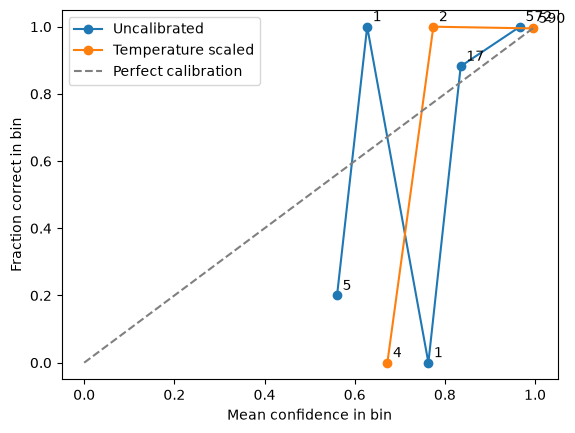

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax

labels = result.label_ids
logits = result.predictions
temperature = optimimzer.x  

def plot_reliability(probabilities, name):
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == labels

    n_bins = 10
    bin_ids = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    counts = np.bincount(bin_ids, minlength=n_bins)
    confidence_sum = np.bincount(bin_ids, weights=confidence, minlength=n_bins)
    correct_sum = np.bincount(bin_ids, weights=correct, minlength=n_bins)

    nonempty = counts > 0
    mean_confidence = confidence_sum[nonempty] / counts[nonempty]
    accuracy = correct_sum[nonempty] / counts[nonempty]

    plt.plot(mean_confidence, accuracy, marker="o", label=name)
    for x, y, count in zip(mean_confidence, accuracy, counts[nonempty]):
        plt.annotate(str(count), (x, y), xytext=(4, 4), textcoords="offset points")

plot_reliability(softmax(logits, axis=1), "Uncalibrated")
plot_reliability(softmax(logits / temperature, axis=1), "Temperature scaled")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.xlabel("Mean confidence in bin")
plt.ylabel("Fraction correct in bin")
plt.legend()
plt.show()

In [23]:
def threshold_testing (threshold):
    accepted = confidence_score >= threshold
    total_accepted = np.count_nonzero(accepted)
    total_rejected = np.count_nonzero(~accepted)
    total_wrong_accepted = np.count_nonzero(accepted & ~comparsion)
    coverage = total_accepted/len(confidence_score)
    review_rate = total_rejected / len(confidence_score)
    accepted_error_rate = total_wrong_accepted / total_accepted
    print(f"Total_accepted: {total_accepted}\nTotal_rejected: {total_rejected}\nTotal_wrong_accepted: {total_wrong_accepted}\nCoverage: {coverage}\nReview_rate: {review_rate}\naccepted_error_rate: {accepted_error_rate}")
   
thresholds = [0.7, 0.8, 0.9, 0.95]
for i in thresholds:
    print(f"For threshold {i}")
    threshold_testing(i)
    print("\n")

For threshold 0.7
Total_accepted: 592
Total_rejected: 4
Total_wrong_accepted: 2
Coverage: 0.9932885906040269
Review_rate: 0.006711409395973154
accepted_error_rate: 0.0033783783783783786


For threshold 0.8
Total_accepted: 591
Total_rejected: 5
Total_wrong_accepted: 2
Coverage: 0.9916107382550335
Review_rate: 0.008389261744966443
accepted_error_rate: 0.00338409475465313


For threshold 0.9
Total_accepted: 586
Total_rejected: 10
Total_wrong_accepted: 2
Coverage: 0.9832214765100671
Review_rate: 0.016778523489932886
accepted_error_rate: 0.0034129692832764505


For threshold 0.95
Total_accepted: 571
Total_rejected: 25
Total_wrong_accepted: 2
Coverage: 0.9580536912751678
Review_rate: 0.04194630872483222
accepted_error_rate: 0.0035026269702276708




In [24]:
messages = load_dataset("csv", data_files="development_challenges.csv")
messages['train'][0:10]

{'message': ['My order hasn’t arrived yet. Can you tell me where it is?',
  'Can I change my order? I want two pieces instead of one',
  'I moved to new adress. Can you update the shipping adress?',
  'Can I talk to an agent?',
  "I didn't get my money back, can you fix this?",
  'I dont want the stuff anymore',
  'I placed an order this morning and need to cancel it before dispatch.',
  'Where is order 4821 right now?',
  "I need help with my order, but I'm not sure what to do.",
  'Do you sell replacement batteries?'],
 'expected_outcome': ['track_order',
  'change_order',
  'change_shipping_address',
  'contact_human_agent',
  'human_review',
  'human_review',
  'cancel_order',
  'track_order',
  'human_review',
  'human_review']}

In [25]:
tokenized_messages = tokenizer(messages['train'][0:10]['message'], padding= True, truncation=True, return_tensors="pt")
output = model(**tokenized_messages)



In [26]:
output.logits.shape
soft = softmax(output.logits.detach().numpy()/optimimzer.x, axis=1) 

np.sum(soft[0])
output.logits.shape


torch.Size([10, 6])

In [27]:
threshold = 0.8

predicted_intents_id =np.argmax(soft, axis=1)
predicted_intents_prob = np.max(soft, axis=1)
model.config.id2label[predicted_intents_id[0]]
for i in range (len(predicted_intents_prob)):
    if predicted_intents_prob[i] > threshold:
        print(model.config.id2label[predicted_intents_id[i]])
    else:
        print("Sent to manual review")



Sent to manual review
change_order
change_shipping_address
contact_human_agent
get_refund
Sent to manual review
change_shipping_address
Sent to manual review
contact_human_agent
Sent to manual review


In [28]:
messages["train"]["expected_outcome"][0:10]

['track_order',
 'change_order',
 'change_shipping_address',
 'contact_human_agent',
 'human_review',
 'human_review',
 'cancel_order',
 'track_order',
 'human_review',
 'human_review']

In [29]:
result_validation_data = trainer.predict(tokenized_validation_data)


c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [30]:
softmaxing_validation_data = softmax(result_validation_data[0] / optimimzer.x, axis=1)
confidence_score_validation_data = np.max(softmaxing_validation_data, axis=1) 

softmax_predictions_validation_data = np.argmax(softmaxing_validation_data, axis=1)
comparsion_validation_data = (softmax_predictions_validation_data == result_validation_data.label_ids)


print(f"Shape of confidence score is: {confidence_score_validation_data.shape} \nThe first 5 values is {confidence_score_validation_data[:5]} " )
print(f"Shape of confidence score is: {comparsion_validation_data.shape} \nThe first 5 values is {comparsion_validation_data[:5]} " )


Shape of confidence score is: (596,) 
The first 5 values is [0.99694751 0.99661317 0.99712305 0.9970832  0.99708836] 
Shape of confidence score is: (596,) 
The first 5 values is [ True  True  True  True  True] 


In [31]:
threshold = 0.8
logits = result_validation_data.predictions
soft = softmax(logits/optimimzer.x, axis=1) 

predicted_intents_id =np.argmax(soft, axis=1)
predicted_intents_prob = np.max(soft, axis=1)
model.config.id2label[predicted_intents_id[0]]

for i in range (len(predicted_intents_prob)):
    if predicted_intents_prob[i] > threshold:
        print(model.config.id2label[predicted_intents_id[i]])
    else:
        print("Sent to manual review")

soft.shape

cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order
cancel_order

(596, 6)

In [32]:
def threshold_testing (threshold):

    accepted = confidence_score_validation_data > threshold
    total_accepted = np.count_nonzero(accepted)
    total_rejected = np.count_nonzero(~accepted)
    total_wrong_accepted = np.count_nonzero(accepted & ~comparsion_validation_data)
    coverage = total_accepted/len(comparsion_validation_data)
    review_rate = total_rejected / len(comparsion_validation_data)

    if total_accepted > 0:
        accepted_error_rate = total_wrong_accepted / total_accepted
    else: 
        accepted_error_rate = None
    print(f"Total_accepted: {total_accepted}\nTotal_rejected: {total_rejected}\nTotal_wrong_accepted: {total_wrong_accepted}\nCoverage: {coverage}\nReview_rate: {review_rate}\naccepted_error_rate: {accepted_error_rate}")


threshold_testing(1)


Total_accepted: 0
Total_rejected: 596
Total_wrong_accepted: 0
Coverage: 0.0
Review_rate: 1.0
accepted_error_rate: None


In [33]:
thresholds = [0.7, 0.8, 0.9, 0.95, 0.99]

for threshold in thresholds:
    print(f"For threshold: {threshold} ")
    threshold_testing(threshold) 
    print('\n')



For threshold: 0.7 
Total_accepted: 592
Total_rejected: 4
Total_wrong_accepted: 3
Coverage: 0.9932885906040269
Review_rate: 0.006711409395973154
accepted_error_rate: 0.005067567567567568


For threshold: 0.8 
Total_accepted: 590
Total_rejected: 6
Total_wrong_accepted: 3
Coverage: 0.9899328859060402
Review_rate: 0.010067114093959731
accepted_error_rate: 0.005084745762711864


For threshold: 0.9 
Total_accepted: 590
Total_rejected: 6
Total_wrong_accepted: 3
Coverage: 0.9899328859060402
Review_rate: 0.010067114093959731
accepted_error_rate: 0.005084745762711864


For threshold: 0.95 
Total_accepted: 579
Total_rejected: 17
Total_wrong_accepted: 2
Coverage: 0.9714765100671141
Review_rate: 0.028523489932885907
accepted_error_rate: 0.0034542314335060447


For threshold: 0.99 
Total_accepted: 561
Total_rejected: 35
Total_wrong_accepted: 0
Coverage: 0.9412751677852349
Review_rate: 0.0587248322147651
accepted_error_rate: 0.0




In [34]:
with open("temprature.txt", 'w') as f:
    f.write(str(temperature))

with open('temprature.txt', 'r') as f:
    loaded_tempratrue = float(f.read())

loaded_tempratrue

0.6723607164744463

In [35]:
import sys
print(sys.executable)

c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Scripts\python.exe


In [ ]:
import joblib

test_data = combined_data[combined_data["split"] == "test"]
test_data.shape

test_data["intent"].value_counts()

tfidf = joblib.load("artifacts/tfidf_baseline.joblib")

output_tfidf1 = tfidf.predict(test_data["instruction"])


print(classification_report(test_data["intent"], output_tfidf1))

                         precision    recall  f1-score   support

           cancel_order       0.00      0.00      0.00       100
           change_order       0.00      0.00      0.00       103
change_shipping_address       0.00      0.00      0.00        96
    contact_human_agent       0.00      0.00      0.00       101
             get_refund       0.17      1.00      0.29       100
            track_order       0.00      0.00      0.00        96

               accuracy                           0.17       596
              macro avg       0.03      0.17      0.05       596
           weighted avg       0.03      0.17      0.05       596



c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alkur\Desktop\Complex Adaptive Systems\Own Projects\support-ticket-assistant\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being